Analyst's prediction (written before results): 4 trend changes in German nights: the 2008 financial crisis, the January 2015 floor removal, covid in 2020, and a post-covid 'new normal' from 2022.

# 02 — FX effect, part A: regimes, FX lags, symmetry

**Why this notebook exists.** The project's deliverable is a forecasting model of monthly hotel nights (canton x origin market, plus the 8 paired resorts), **1 to 6 months ahead**. This notebook designs its features by answering three questions:

1. **Regimes** — when did the trend of German, Swiss and US nights break? Is the post-covid period a new normal?
2. **FX lags** — which lags of EUR/CHF are linked to German nights? Forecast features must be lagged **at least 6 months** (the longest horizon), so lags 6-12 are the usable set.
3. **Symmetry** — does a stronger franc move nights as much as a weaker one?

**Rules fixed before looking at results** (coded in `src/fx_effect.py`):
- Change points: PELT, piecewise-linear trend (each regime has its own level and slope), penalty = 3 x sigma^2 x ln(n) (BIC-style: level, slope, break date), sigma from the MAD of month-to-month changes, minimum regime 12 months. Main run on the full period; pre-covid run as a sensitivity check; Binseg forced to 1-5 breaks as a second sensitivity check.
- Seasonality removed first: log(nights) minus its month-of-year mean.
- Post-covid vs 2016-2019: the 2016-2019 trend is extrapolated over the post-covid regime; an average gap within +/-5% counts as "back to the pre-covid path".
- FX regressions: y = YoY log change of nights, x = YoY log change of CHF per EUR (x > 0 = weaker franc). Months whose YoY change touches covid (Mar 2020 - Dec 2021, in t or t-12) are excluded, i.e. through Dec 2022. Newey-West (HAC, 12 lags) standard errors, because YoY changes overlap. Only **sums** of lag coefficients are interpreted.
- Feature decisions: FX lag window chosen by BIC among lags 6..L; split FX into appreciation/depreciation only if the Wald test on lags 6-12 rejects symmetry at 5%.
- Swiss nights are a placebo: same regressions, but a strong franc also makes holidays abroad cheaper for Swiss residents, so it is not a clean control.

Language is descriptive: "linked to", "moves with", never "causes".

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
from charts import (INK_SOFT, ORIGIN_COLORS, SOURCE_BFS, SOURCE_BFS_SNB, add_source, connect,
                    save, set_style, shade_covid, year_axis)
from features import deseasonalized_log, yoy_log_change
import fx_effect as fe

set_style()
pd.set_option("display.precision", 3)
con = connect()

nights = con.sql("""
    SELECT date, geo, origin, nights FROM monthly_nights WHERE level = 'canton'
""").df()
nights["date"] = pd.to_datetime(nights["date"])
assert (nights.groupby(["date", "origin"])["geo"].nunique() == 7).all(), "missing canton-month"
total = nights.groupby(["origin", "date"])["nights"].sum()     # sum of 7 cantons

eur = con.sql("SELECT date, chf_per_unit FROM fx WHERE currency = 'EUR' ORDER BY date").df()
eur = eur.assign(date=pd.to_datetime(eur["date"])).set_index("date")["chf_per_unit"].rename("EUR/CHF")

MARKETS = ["Germany", "Switzerland", "United States"]
series = {m: total[m].rename(m) for m in MARKETS}
print({m: f"{s.index.min():%Y-%m} -> {s.index.max():%Y-%m} ({len(s)} months)" for m, s in series.items()})
print(f"EUR/CHF: {eur.index.min():%Y-%m} -> {eur.index.max():%Y-%m} ({len(eur)} months)")

{'Germany': '2005-01 -> 2026-07 (259 months)', 'Switzerland': '2005-01 -> 2026-07 (259 months)', 'United States': '2005-01 -> 2026-07 (259 months)'}
EUR/CHF: 2005-08 -> 2026-08 (253 months)


## 1. Trend regimes (change points)

In [2]:
PRE_COVID_END = "2020-02-01"
des = {m: deseasonalized_log(s) for m, s in series.items()}

breaks, breaks_pre, segments, fits = {}, {}, {}, {}
for m, y in des.items():
    breaks[m] = fe.detect_breaks(y)
    breaks_pre[m] = fe.detect_breaks(y[:PRE_COVID_END])
    segments[m], fits[m] = fe.segment_table(y, breaks[m])

fx_log = np.log(eur).rename("EUR/CHF")
breaks["EUR/CHF"] = fe.detect_breaks(fx_log)
breaks_pre["EUR/CHF"] = fe.detect_breaks(fx_log[:PRE_COVID_END])

fmt = lambda bs: ", ".join(f"{b:%Y-%m}" for b in bs) or "none"
summary = pd.DataFrame({
    "breaks_full_period": {k: fmt(v) for k, v in breaks.items()},
    "n_full": {k: len(v) for k, v in breaks.items()},
    "breaks_pre_covid": {k: fmt(v) for k, v in breaks_pre.items()},
    "n_pre": {k: len(v) for k, v in breaks_pre.items()},
})
summary

,breaks_full_period,n_full,breaks_pre_covid,n_pre
Germany,"2006-01, 2007-01, 2011-07, 2015-06, 2020-03, 2...",6,"2006-01, 2007-01, 2011-07, 2015-06",4
Switzerland,"2006-01, 2016-06, 2019-06, 2020-06, 2021-07",5,"2006-01, 2017-01",2
United States,"2008-06, 2017-04, 2018-04, 2019-04, 2020-04, 2...",8,"2006-02, 2007-02, 2008-06, 2011-07, 2017-04, 2...",6
EUR/CHF,"2007-05, 2008-10, 2009-10, 2010-10, 2011-10, 2...",15,"2007-05, 2008-10, 2009-10, 2010-10, 2011-10, 2...",11


Regimes per market (full period): slope of the deseasonalized log series in each regime.

In [3]:
pd.concat({m: segments[m] for m in MARKETS}, names=["market", "regime"])

start      end  months  slope_pct_per_year
market        regime                                              
Germany       0       2005-01  2005-12      12             -26.498
              1       2006-01  2006-12      12             -19.208
              2       2007-01  2011-06      54              -2.776
              3       2011-07  2015-05      47              -3.259
              4       2015-06  2020-02      57               2.447
              5       2020-03  2021-06      16             115.441
              6       2021-07  2026-07      61               2.059
Switzerland   0       2005-01  2005-12      12             -11.267
              1       2006-01  2016-05     125               0.635
              2       2016-06  2019-05      36               5.729
              3       2019-06  2020-05      12             -72.271
              4       2020-06  2021-06      13              15.266
              5       2021-07  2026-07      61               0.543
United States 0       2005-01  2008-05      41               3.500
              1       2008-06  2017-03     106               3.659
              2       2017-04  2018-03      12             -16.809
              3       2018-04  2019-03      12             -12.850
              4       2019-04  2020-03      12             -52.018
              5       2020-04  2021-06      15             251.208
              6       2021-07  2022-06      12             312.027
              7       2022-07  2024-03      21              15.096
              8       2024-04  2026-07      28               2.125

**Sensitivity:** break dates when Binseg is forced to find exactly 1 to 5 breaks (full period).

In [4]:
forced = pd.concat([fe.forced_breaks(des[m]) for m in MARKETS] + [fe.forced_breaks(fx_log)], axis=1)
forced

,Germany,Switzerland,United States,EUR/CHF
n_breaks,,,,
1,2020-03,2021-04,2020-04,2010-06
2,"2020-03, 2021-07","2020-03, 2021-04","2020-04, 2022-06","2010-06, 2017-08"
3,"2011-07, 2020-03, 2021-07","2015-05, 2020-03, 2021-04","2008-06, 2020-04, 2022-06","2010-06, 2015-01, 2017-08"
4,"2011-07, 2015-06, 2020-03, 2021-07","2015-05, 2020-03, 2021-04, 2022-04","2008-06, 2020-04, 2021-06, 2022-06","2008-01, 2010-06, 2015-01, 2017-08"
5,"2006-01, 2011-07, 2015-06, 2020-03, 2021-07","2006-01, 2015-05, 2020-03, 2021-04, 2022-04","2008-06, 2019-04, 2020-04, 2021-06, 2022-06","2008-01, 2010-06, 2011-06, 2015-01, 2017-08"


**Analyst's prediction vs data** (German nights). The prediction in the first cell is not edited.

In [5]:
predicted = {"2008 financial crisis": "2008", "Jan 2015 floor removal": "2015-01",
             "covid 2020": "2020", "post-covid new normal": "2022"}
found = [f"{b:%Y-%m}" for b in breaks["Germany"]]
print(f"Predicted: 4 trend changes ({', '.join(predicted)}).")
print(f"Found by PELT (full period): {len(found)} breaks: {', '.join(found)}.")
for event, key in predicted.items():
    hits = [f for f in found if f.startswith(key[:4])]
    print(f"  {event:<24} -> {'found: ' + ', '.join(hits) if hits else 'no break that year'}")

Predicted: 4 trend changes (2008 financial crisis, Jan 2015 floor removal, covid 2020, post-covid new normal).
Found by PELT (full period): 6 breaks: 2006-01, 2007-01, 2011-07, 2015-06, 2020-03, 2021-07.
  2008 financial crisis    -> no break that year
  Jan 2015 floor removal   -> found: 2015-06
  covid 2020               -> found: 2020-03
  post-covid new normal    -> no break that year


### Chart 7 — Trend regimes of German, Swiss and US nights

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/07_change_points.png')

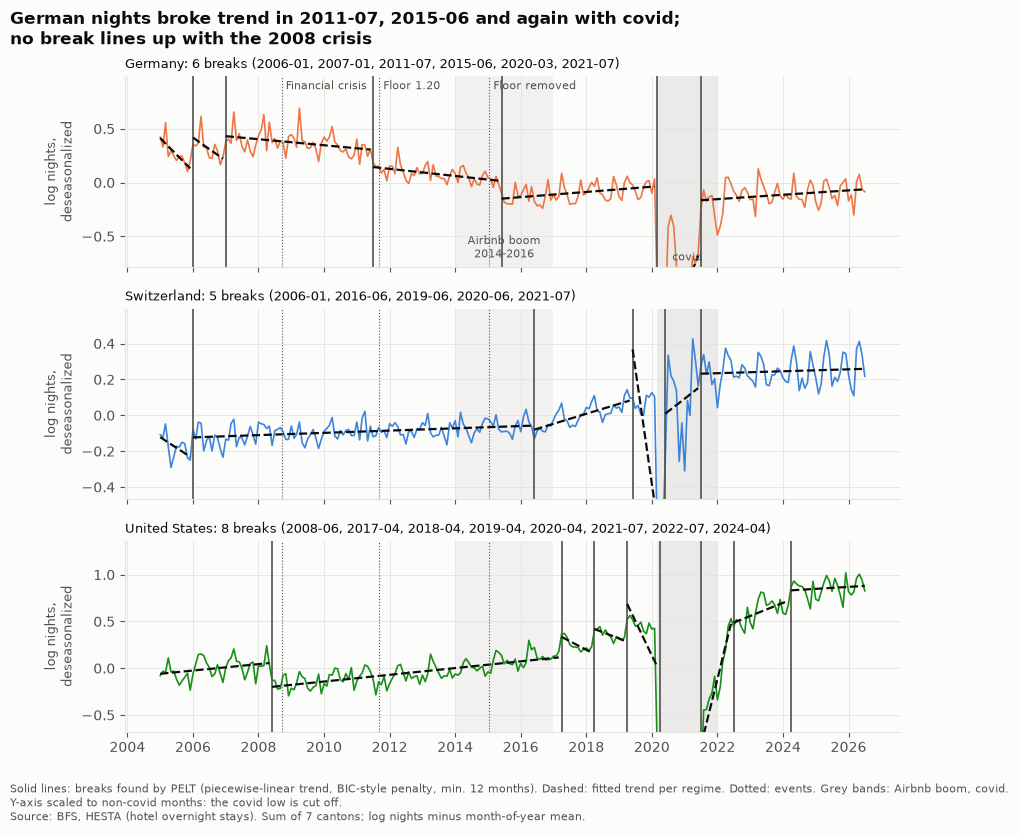

In [6]:
EVENTS = [("2008-09-15", "Financial crisis"), ("2011-09-06", "Floor 1.20"),
          ("2015-01-15", "Floor removed")]
fig, axes = plt.subplots(3, 1, figsize=(10, 8.4), sharex=True)
for ax, m in zip(axes, MARKETS):
    ax.axvspan(pd.Timestamp("2014-01-01"), pd.Timestamp("2016-12-31"), color=INK_SOFT,
               alpha=0.06, lw=0, zorder=0)
    shade_covid(ax, label=ax is axes[0])
    ax.plot(des[m].index, des[m], color=ORIGIN_COLORS[m], lw=1.2, alpha=0.9)
    for start in breaks[m]:                                 # one line per regime
        ax.axvline(start, color=INK_SOFT, lw=1.2)
    seg_id = np.searchsorted(np.array(breaks[m], dtype="datetime64[ns]"), fits[m].index.values, side="right")
    for k in np.unique(seg_id):
        part = fits[m][seg_id == k]
        ax.plot(part.index, part, color="#0b0b0b", lw=1.6, ls="--")
    for d, _ in EVENTS:
        ax.axvline(pd.Timestamp(d), color=INK_SOFT, lw=0.8, ls=":")
    ax.set_ylabel("log nights,\ndeseasonalized", fontsize=9)
    ax.set_title(f"{m}: {len(breaks[m])} breaks ({fmt(breaks[m])})", loc="left", fontsize=9,
                 fontweight="normal")
    # Covid plunge would flatten every other regime: scale on non-covid months
    calm = des[m][(des[m].index < "2020-03-01") | (des[m].index > "2021-12-01")]
    pad = 0.25 * (calm.max() - calm.min())
    ax.set_ylim(calm.min() - pad, calm.max() + pad)
for d, text in EVENTS:
    axes[0].annotate(text, xy=(pd.Timestamp(d), 0.98), xycoords=("data", "axes fraction"),
                     xytext=(3, 0), textcoords="offset points", va="top", fontsize=8, color=INK_SOFT)
axes[0].annotate("Airbnb boom\n2014-2016", xy=(pd.Timestamp("2015-07-01"), 0.03),
                 xycoords=("data", "axes fraction"), ha="center", va="bottom", fontsize=8, color=INK_SOFT)
year_axis(axes[-1])
de_b = [b for b in breaks["Germany"] if b < pd.Timestamp("2020-01-01") and b >= pd.Timestamp("2008-01-01")]
fig.suptitle(f"German nights broke trend in {fmt(de_b)} and again with covid;\n"
             f"no break lines up with the 2008 crisis", x=0.01, ha="left", fontsize=12,
             fontweight="bold")
add_source(fig, SOURCE_BFS + ". Sum of 7 cantons; log nights minus month-of-year mean.",
           "Solid lines: breaks found by PELT (piecewise-linear trend, BIC-style penalty, min. 12 months). "
           "Dashed: fitted trend per regime. Dotted: events. Grey bands: Airbnb boom, covid.\n"
           "Y-axis scaled to non-covid months: the covid low is cut off.")
fig.subplots_adjust(bottom=0.12, top=0.9, hspace=0.22)
save(fig, "07_change_points")

### Post-covid regime vs 2016-2019

In [7]:
post = pd.DataFrame([fe.post_covid_vs_path(des[m], breaks[m]) for m in MARKETS]).set_index("market")
display(post)
for m, r in post.iterrows():
    print(f"{m}: post-covid regime (from {r.post_covid_from}) is {r.level_vs_2016_19_pct:+.1f}% vs the "
          f"2016-2019 level, growing {r.slope_post_covid_pct_yr:+.1f}%/yr vs {r.slope_2016_19_pct_yr:+.1f}%/yr "
          f"before, {r.gap_vs_2016_19_path_pct:+.1f}% vs the extrapolated 2016-2019 path -> {r.verdict}.")

,post_covid_from,level_vs_2016_19_pct,slope_2016_19_pct_yr,slope_post_covid_pct_yr,gap_vs_2016_19_path_pct,verdict
market,,,,,,
Germany,2021-07,-2.456,2.393,2.056,-15.445,"new normal, below the pre-covid path"
Switzerland,2021-07,27.074,3.995,0.540,0.293,back to the pre-covid path
United States,2024-04,77.931,10.570,2.105,-15.553,"new normal, below the pre-covid path"


Germany: post-covid regime (from 2021-07) is -2.5% vs the 2016-2019 level, growing +2.1%/yr vs +2.4%/yr before, -15.4% vs the extrapolated 2016-2019 path -> new normal, below the pre-covid path.
Switzerland: post-covid regime (from 2021-07) is +27.1% vs the 2016-2019 level, growing +0.5%/yr vs +4.0%/yr before, +0.3% vs the extrapolated 2016-2019 path -> back to the pre-covid path.
United States: post-covid regime (from 2024-04) is +77.9% vs the 2016-2019 level, growing +2.1%/yr vs +10.6%/yr before, -15.6% vs the extrapolated 2016-2019 path -> new normal, below the pre-covid path.


## 2. Which FX lags?

Symmetric model first. Individual lag coefficients are not identified (consecutive YoY changes share 11 of 12 months), so only sums are read.

In [8]:
x = yoy_log_change(eur)
yoy = {m: yoy_log_change(series[m]).rename(m) for m in ["Germany", "Switzerland"]}

# One common sample for every model: all lags 0-12 available, no covid in t or t-12
masks = {m: fe.sample_mask(y, fe.fx_lags(x.reindex(y.index), range(0, 13), split=True))
         for m, y in yoy.items()}
for m, mk in masks.items():
    idx = mk[mk].index
    print(f"{m}: N = {mk.sum()}, {idx.min():%Y-%m} -> {idx.max():%Y-%m}, "
          f"gap {idx[idx < '2021-01-01'].max():%Y-%m} -> {idx[idx > '2021-01-01'].min():%Y-%m}")
assert masks["Germany"].equals(masks["Switzerland"])

cum = pd.concat([fe.cumulative_effect(y, x.reindex(y.index), range(0, 13), masks[m])
                 for m, y in yoy.items()])
cum.pivot(index="lag", columns="market", values="cum_effect")

Germany: N = 194, 2007-08 -> 2026-07, gap 2020-02 -> 2023-01
Switzerland: N = 194, 2007-08 -> 2026-07, gap 2020-02 -> 2023-01


market,Germany,Switzerland
lag,,
0,-0.553,-0.085
1,0.325,0.036
2,0.409,0.365
3,0.445,-0.089
4,0.319,0.054
5,1.237,0.057
6,-0.046,0.041
7,1.216,0.071
8,0.828,0.469


The cumulative sum jumps from lag to lag, confirming that single lags cannot be read. For the forecast, only lags >= 6 can be used. BIC compares windows 6..L on the same sample:

In [9]:
win = pd.concat([fe.lag_window_bic(y, x.reindex(y.index), 6, 12, masks[m]) for m, y in yoy.items()],
                ignore_index=True)
best = win.loc[win.groupby("market")["bic"].idxmin()].set_index("market")
lag_text = lambda r: (f"lag 6 only" if r.last_lag == 6 else f"lags 6-{r.last_lag}")
display(win.pivot(index="lags", columns="market", values=["bic", "sum_effect", "p_sum"]))
for m, r in best.iterrows():
    print(f"{m}: BIC prefers {lag_text(r)}; summed effect {r.sum_effect:.2f} "
          f"(95% CI {r.sum_effect - 1.96 * r.se_sum:.2f} to {r.sum_effect + 1.96 * r.se_sum:.2f}, "
          f"p = {r.p_sum:.4f}, N = {r.N}).")

bic             sum_effect                  p_sum            
market  Germany Switzerland    Germany Switzerland    Germany Switzerland
lags                                                                     
6-10   -299.349    -637.205      0.684       0.224  3.252e-04   1.389e-05
6-11   -304.249    -638.569      0.774       0.255  1.090e-05   5.957e-06
6-12   -299.334    -634.193      0.793       0.267  6.849e-06   5.632e-06
6-6    -316.399    -649.942      0.631       0.187  4.437e-04   3.621e-04
6-7    -314.383    -648.073      0.673       0.205  1.939e-04   6.098e-05
6-8    -309.317    -644.412      0.660       0.220  1.489e-04   2.758e-05
6-9    -304.050    -640.667      0.660       0.206  2.347e-04   9.421e-05

Germany: BIC prefers lag 6 only; summed effect 0.63 (95% CI 0.28 to 0.98, p = 0.0004, N = 194).
Switzerland: BIC prefers lag 6 only; summed effect 0.19 (95% CI 0.08 to 0.29, p = 0.0004, N = 194).


### Chart 8 — Summed FX effect for the usable lag windows (6..L)

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/08_fx_lag_windows.png')

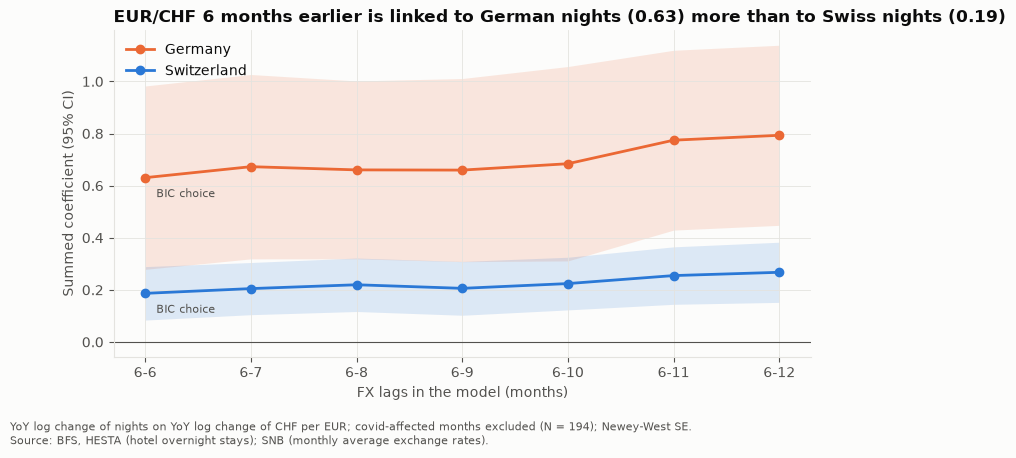

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for m in ["Germany", "Switzerland"]:
    w = win[win["market"] == m]
    ax.plot(w["last_lag"], w["sum_effect"], marker="o", color=ORIGIN_COLORS[m], label=m)
    ax.fill_between(w["last_lag"], w["sum_effect"] - 1.96 * w["se_sum"],
                    w["sum_effect"] + 1.96 * w["se_sum"], color=ORIGIN_COLORS[m], alpha=0.15, lw=0)
    b = best.loc[m]
    ax.annotate("BIC choice", xy=(b.last_lag, b.sum_effect), xytext=(8, -14),
                textcoords="offset points", fontsize=8, color=INK_SOFT)
ax.axhline(0, color=INK_SOFT, lw=0.8)
ax.set_xticks(range(6, 13), [f"6-{k}" for k in range(6, 13)])
ax.set_xlabel("FX lags in the model (months)")
ax.set_ylabel("Summed coefficient (95% CI)")
ax.legend(loc="upper left")
de, ch = best.loc["Germany"], best.loc["Switzerland"]
ax.set_title(f"EUR/CHF 6 months earlier is linked to German nights ({de.sum_effect:.2f}) "
             f"more than to Swiss nights ({ch.sum_effect:.2f})", loc="left", fontsize=12)
add_source(fig, SOURCE_BFS_SNB + ".",
           f"YoY log change of nights on YoY log change of CHF per EUR; covid-affected months excluded "
           f"(N = {de.N}); Newey-West SE.")
fig.subplots_adjust(bottom=0.2)
save(fig, "08_fx_lag_windows")

## 3. Symmetric or asymmetric?

FX change split into depreciation (franc weakens, x > 0) and appreciation (franc strengthens, x < 0) parts. Positive sums mean nights move in the same direction as EUR/CHF (stronger franc, fewer nights). Wald H0: the two sums are equal. Lags 0-12 as designed; lags 6-12 is the set usable in a 6-month-ahead forecast. Swiss nights = placebo.

In [11]:
rows = []
for lags in [range(0, 13), range(6, 13)]:
    for m, y in yoy.items():
        rows.append(fe.asymmetry_test(y, x.reindex(y.index), lags, masks[m]))
asym = pd.DataFrame(rows).set_index(["lags", "market"])
display(asym)

for (lags, m), r in asym.iterrows():
    verdict = "asymmetry supported" if r.wald_p < fe.ALPHA else "asymmetry not supported"
    print(f"{m}, lags {lags}: appreciation sum {r.sum_appreciation:.2f} (p = {r.p_app:.4f}), "
          f"depreciation sum {r.sum_depreciation:.2f} (p = {r.p_dep:.4f}); "
          f"Wald p = {r.wald_p:.4f} -> {verdict} at 5% (N = {int(r.N)}).")

N  sum_appreciation  se_app      p_app  sum_depreciation  \
lags market                                                                    
0-12 Germany      194             1.492   0.228  5.826e-11            -0.338   
     Switzerland  194             0.149   0.106  1.575e-01             0.788   
6-12 Germany      194             1.009   0.210  1.498e-06             0.216   
     Switzerland  194             0.219   0.090  1.527e-02             0.428   

                  se_dep      p_dep  wald_stat  wald_p  
lags market                                             
0-12 Germany       0.427  4.292e-01     10.057   0.002  
     Switzerland   0.201  8.562e-05      5.530   0.019  
6-12 Germany       0.310  4.860e-01      3.454   0.063  
     Switzerland   0.146  3.293e-03      0.977   0.323

Germany, lags 0-12: appreciation sum 1.49 (p = 0.0000), depreciation sum -0.34 (p = 0.4292); Wald p = 0.0015 -> asymmetry supported at 5% (N = 194).
Switzerland, lags 0-12: appreciation sum 0.15 (p = 0.1575), depreciation sum 0.79 (p = 0.0001); Wald p = 0.0187 -> asymmetry supported at 5% (N = 194).
Germany, lags 6-12: appreciation sum 1.01 (p = 0.0000), depreciation sum 0.22 (p = 0.4860); Wald p = 0.0631 -> asymmetry not supported at 5% (N = 194).
Switzerland, lags 6-12: appreciation sum 0.22 (p = 0.0153), depreciation sum 0.43 (p = 0.0033); Wald p = 0.3229 -> asymmetry not supported at 5% (N = 194).


### Chart 9 — Appreciation vs depreciation effects

PosixPath('/Users/yasserpaulino/Desktop/swiss-tourism-fx/reports/figures/09_asymmetry.png')

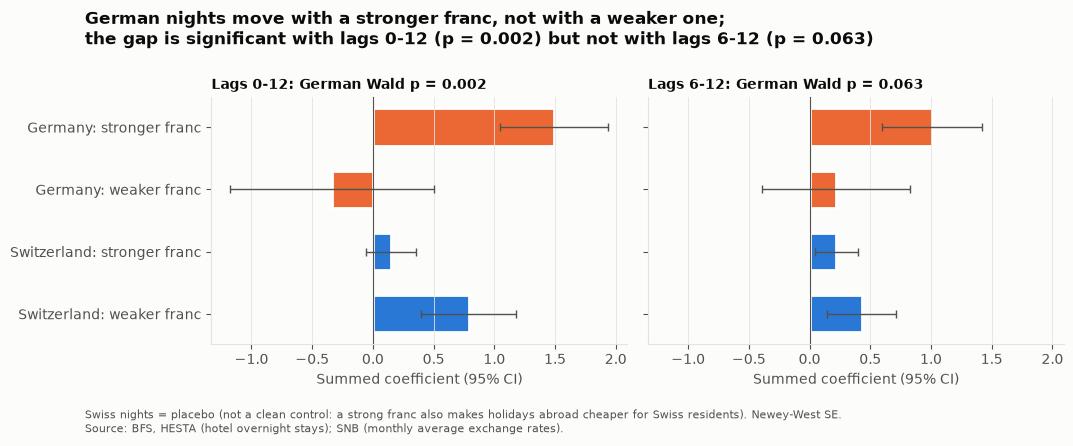

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True)
for ax, lags in zip(axes, ["0-12", "6-12"]):
    labels, est, se, col = [], [], [], []
    for m in ["Switzerland", "Germany"]:
        r = asym.loc[(lags, m)]
        for part, e, s in [("weaker franc", r.sum_depreciation, r.se_dep),
                           ("stronger franc", r.sum_appreciation, r.se_app)]:
            labels.append(f"{m}: {part}"); est.append(e); se.append(s); col.append(ORIGIN_COLORS[m])
    y = np.arange(len(labels))
    ax.barh(y, est, xerr=1.96 * np.array(se), color=col, height=0.6, edgecolor="white",
            linewidth=2, error_kw={"ecolor": INK_SOFT, "lw": 1, "capsize": 3})
    ax.set_yticks(y, labels if ax is axes[0] else [""] * len(labels))
    ax.axvline(0, color=INK_SOFT, lw=0.8)
    ax.grid(axis="y", visible=False)
    de_p = asym.loc[(lags, "Germany"), "wald_p"]
    ax.set_title(f"Lags {lags}: German Wald p = {de_p:.3f}", loc="left", fontsize=10)
    ax.set_xlabel("Summed coefficient (95% CI)")
p012, p612 = asym.loc[("0-12", "Germany"), "wald_p"], asym.loc[("6-12", "Germany"), "wald_p"]
fig.suptitle(f"German nights move with a stronger franc, not with a weaker one;\nthe gap is "
             f"significant with lags 0-12 (p = {p012:.3f}) but not with lags 6-12 (p = {p612:.3f})",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
add_source(fig, SOURCE_BFS_SNB + ".", "Swiss nights = placebo (not a clean control: a strong franc "
           "also makes holidays abroad cheaper for Swiss residents). Newey-West SE.")
fig.subplots_adjust(bottom=0.22, top=0.78, wspace=0.05)
save(fig, "09_asymmetry")

## Feature spec for Sprint 3

Target: monthly hotel nights for **49 series (7 cantons x 7 origin markets)** plus the **total of each of the 8 paired resorts** (luxury vs mid-range), forecast **1 to 6 months ahead**, for seasonal pricing and seasonal staffing. Error is reported overall and for **peak-season months** (when seasonal staff is hired), always next to the seasonal-naive baseline. The decisions below are printed from this notebook's results:

In [13]:
de_post = post.loc["Germany"]
pre_breaks = [b for b in breaks["Germany"] if pd.Timestamp("2008-01-01") <= b < pd.Timestamp("2020-01-01")]
split = asym.loc[("6-12", "Germany"), "wald_p"] < fe.ALPHA

spec = [
    "REGIMES / COVID",
    f"  - Covid indicator Mar 2020 - Dec 2021 (PELT puts the German covid regime at "
    f"{fmt([b for b in breaks['Germany'] if b.year in (2020, 2021)])}).",
    f"  - Post-covid level indicator from {de_post.post_covid_from} for Germany ({de_post.verdict}); "
    f"Switzerland: {post.loc['Switzerland', 'verdict']}; United States: {post.loc['United States', 'verdict']}.",
    f"  - German pre-covid trend breaks at {fmt(pre_breaks)}: let the model's trend change there "
    f"(piecewise trend or regime indicator), re-detected inside each training window to avoid look-ahead.",
    "FX LAGS",
    f"  - Feature: YoY log change of the market's currency vs CHF, {lag_text(best.loc['Germany'])} "
    f"(BIC choice for Germany; Switzerland: {lag_text(best.loc['Switzerland'])}). Lags < 6 are not allowed "
    f"at a 6-month horizon; shorter-horizon models may only use FX known at the forecast origin.",
    f"  - Linked effect for Germany: summed coefficient {best.loc['Germany', 'sum_effect']:.2f} "
    f"(p = {best.loc['Germany', 'p_sum']:.4f}).",
    "SYMMETRY",
    f"  - Wald test on lags 6-12 for Germany: p = {asym.loc[('6-12', 'Germany'), 'wald_p']:.3f} -> "
    + ("split FX into appreciation and depreciation features." if split else
       "keep ONE symmetric FX feature (rule: split only if p < 0.05). With lags 0-12, p = "
       f"{asym.loc[('0-12', 'Germany'), 'wald_p']:.4f}: test the split as a Sprint 3 experiment, "
       "judged by forecast error, not by p-value."),
    "SCENARIOS",
    "  - FX inside the 6-month horizon enters only as scenarios (e.g. EUR/CHF at 0.90), not as a forecast input.",
]
print("\n".join(spec))

REGIMES / COVID
  - Covid indicator Mar 2020 - Dec 2021 (PELT puts the German covid regime at 2020-03, 2021-07).
  - Post-covid level indicator from 2021-07 for Germany (new normal, below the pre-covid path); Switzerland: back to the pre-covid path; United States: new normal, below the pre-covid path.
  - German pre-covid trend breaks at 2011-07, 2015-06: let the model's trend change there (piecewise trend or regime indicator), re-detected inside each training window to avoid look-ahead.
FX LAGS
  - Feature: YoY log change of the market's currency vs CHF, lag 6 only (BIC choice for Germany; Switzerland: lag 6 only). Lags < 6 are not allowed at a 6-month horizon; shorter-horizon models may only use FX known at the forecast origin.
  - Linked effect for Germany: summed coefficient 0.63 (p = 0.0004).
SYMMETRY
  - Wald test on lags 6-12 for Germany: p = 0.063 -> keep ONE symmetric FX feature (rule: split only if p < 0.05). With lags 0-12, p = 0.0015: test the split as a Sprint 3 experiment

## Limitations

- **Hotels only.** HESTA does not cover holiday flats or Airbnb: a shift of German guests to them would look like lost demand, and the 2014-2016 Airbnb boom overlaps the 2015 floor removal.
- **Overlapping events.** The 2008 crisis and the franc surge, and the 2015 floor removal and the Airbnb boom, happen at the same time; regimes cannot be attributed to one cause.
- **Short pre-covid windows.** 2016-2019 is four years; extrapolating its trend to 2026 (post-covid comparison) is a strong assumption.
- **Break detection on the full sample** uses future data; it describes the past. Sprint 3 must re-detect breaks inside each training window.
- **YoY regressions:** overlapping changes, few independent FX episodes (2011, 2015, 2022), and a placebo that is not clean. Results are associations, not causal effects.
- **EUR/CHF is not trend-stationary**, so a piecewise-linear trend model splits it into many short regimes; its breaks are shown for comparison only.
- **Out of scope:** overbooking and nightly pricing need daily, hotel-level data (cancellations, no-shows, capacity), which this project does not have.

In [14]:
con.close()
print(sorted(p.name for p in (Path.cwd().resolve().parent / "reports" / "figures").glob("0[7-9]_*.png")))

['07_change_points.png', '08_fx_lag_windows.png', '09_asymmetry.png']
